In [1]:
!pip install -q -U ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 43.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 4.7 MB/s eta 0:00:00


In [2]:
import torch
import ultralytics

print("Ultralytics:", ultralytics.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError("Enable a GPU in Kaggle Notebook Settings.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics: 8.4.178
GPU available: True
GPU name: Tesla T4


In [3]:
from pathlib import Path

input_root = Path("/kaggle/input")

candidates = [
    input_root / "datasets/gabrielfcarvalho/cardd-with-yolo-annotations-images-labels",
    input_root / "cardd-with-yolo-annotations-images-labels",
]

BASE = next(
    (p for p in candidates if (p / "train/images").is_dir()),
    None
)

# Fallback: search for the train folder if Kaggle mounted it elsewhere.
if BASE is None:
    for train_dir in input_root.rglob("train"):
        if (train_dir / "images").is_dir():
            BASE = train_dir.parent
            break

if BASE is None:
    print("Datasets attached to this notebook:")
    for p in input_root.iterdir():
        print(p)
    raise FileNotFoundError(
        "Could not find the dataset folder containing train/images."
    )

print("Dataset root:", BASE)

for split in ["train", "val", "test"]:
    img_dir = BASE / split / "images"
    label_dir = BASE / split / "labels"

    image_count = (
        sum(
            1 for p in img_dir.iterdir()
            if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
        )
        if img_dir.is_dir() else 0
    )

    label_count = (
        len(list(label_dir.glob("*.txt")))
        if label_dir.is_dir() else 0
    )

    print(
        f"{split}: {image_count} images, "
        f"{label_count} label files"
    )

Dataset root: /kaggle/input/datasets/gabrielfcarvalho/cardd-with-yolo-annotations-images-labels
train: 2816 images, 2816 label files
val: 810 images, 810 label files
test: 374 images, 374 label files


In [4]:
import yaml

CLASS_NAMES = [
    "dent",
    "scratch",
    "crack",
    "glass shatter",
    "lamp broken",
    "tire flat",
]

data_config = {
    "path": str(BASE),
    "train": "train/images",
    "val": "val/images",
    "nc": len(CLASS_NAMES),
    "names": CLASS_NAMES,
}

if (BASE / "test/images").is_dir():
    data_config["test"] = "test/images"

DATA_YAML = Path("/kaggle/working/car_damage.yaml")

with open(DATA_YAML, "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

print(DATA_YAML.read_text())

path: /kaggle/input/datasets/gabrielfcarvalho/cardd-with-yolo-annotations-images-labels
train: train/images
val: val/images
nc: 6
names:
- dent
- scratch
- crack
- glass shatter
- lamp broken
- tire flat
test: test/images



In [5]:
from collections import Counter

for split in ["train", "val", "test"]:
    label_dir = BASE / split / "labels"

    if not label_dir.is_dir():
        print(f"{split}: no labels folder")
        continue

    counts = Counter()

    for label_file in label_dir.glob("*.txt"):
        for line in label_file.read_text().splitlines():
            parts = line.strip().split()

            if not parts:
                continue

            if len(parts) != 5:
                print("Unexpected annotation:", label_file, line)
                continue

            class_id = int(parts[0])
            counts[class_id] += 1

    print(f"\n{split} class counts:")
    for class_id, name in enumerate(CLASS_NAMES):
        print(f"  {class_id} - {name}: {counts[class_id]}")


train class counts:
  0 - dent: 1806
  1 - scratch: 2560
  2 - crack: 651
  3 - glass shatter: 475
  4 - lamp broken: 494
  5 - tire flat: 225

val class counts:
  0 - dent: 501
  1 - scratch: 728
  2 - crack: 177
  3 - glass shatter: 135
  4 - lamp broken: 141
  5 - tire flat: 62

test class counts:
  0 - dent: 236
  1 - scratch: 307
  2 - crack: 70
  3 - glass shatter: 71
  4 - lamp broken: 69
  5 - tire flat: 32


In [6]:
import torch
from ultralytics import YOLO

# Check the available GPUs
gpu_count = torch.cuda.device_count()

if gpu_count >= 2:
    device = [0, 1]
    batch_size = 32
else:
    device = 0
    batch_size = 8

print("GPU count:", gpu_count)
print("Device:", device)
print("Batch size:", batch_size)

# Load pretrained YOLO26n
model = YOLO("yolo26s.pt")

results = model.train(
    data=str(DATA_YAML),
    epochs=50,
    batch=batch_size,
    imgsz=1024,
    device=device,
    workers=4,

    # Optimization
    optimizer="AdamW",
    cos_lr=True,
    lr0=0.0003,
    lrf=0.01,
    weight_decay=0.0005,
    warmup_epochs=5,

    # Loss weights
    box=7.5,
    cls=0.5,
    dfl=1.5,

    # Training controls
    patience=20,
    pretrained=True,
    amp=True,
    save=True,
    save_period=10,
    seed=42,

    # Augmentation for car damage
    flipud=0.0,
    fliplr=0.5,
    mosaic=1.0,
    close_mosaic=10,
    mixup=0.05,
    copy_paste=0.0,
    degrees=5.0,
    scale=0.5,

    # Keep this run separate from the baseline
    project="/kaggle/working/runs",
    name="yolo26n_cardd_tuned_1024",
    plots=True
)

GPU count: 2
Device: [0, 1]
Batch size: 32
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/car_damage.yaml, degrees=5.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, iou=0.7, kobj=1.0, line_width=None, lr0=0.0003, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.05, mode=

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       2/50      11.9G      1.555      2.908    0.01992         79       1024: 100% ━━━━━━━━━━━━ 88/88 1.5it/s 59.9s0.7ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 1.5it/s 8.6s0.7s
                   all        810       1744      0.397      0.207       0.23        0.1

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/50      11.9G      1.505      2.492    0.01974         81       1024: 100% ━━━━━━━━━━━━ 88/88 1.5it/s 59.2s0.7ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 1.3it/s 9.9s0.6s
                   all        810       1744      0.567      0.482      0.495      0.267

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/50      11.9G      1.454      2.336    0.01884         87       1024: 

In [7]:
from pathlib import Path
from ultralytics import YOLO

run_dir = Path(model.trainer.save_dir)
best_weights = run_dir / "weights" / "best.pt"

print("Training results:", run_dir)
print("Best weights:", best_weights)
assert best_weights.exists(), "The best model checkpoint was not found."

best_model = YOLO(str(best_weights))

val_metrics = best_model.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=640,
    batch=8,
    device=0,
    plots=True
)

metrics = val_metrics.box

print(f"Precision:    {metrics.mp:.4f}")
print(f"Recall:       {metrics.mr:.4f}")
print(f"mAP@0.5:      {metrics.map50:.4f}")
print(f"mAP@0.5:0.95: {metrics.map:.4f}")

print("\nPer-class mAP@0.5:0.95:")
for class_id, class_name in best_model.names.items():
    print(f"{class_name}: {metrics.maps[class_id]:.4f}")

Training results: /kaggle/working/runs/yolo26n_cardd_tuned_1024
Best weights: /kaggle/working/runs/yolo26n_cardd_tuned_1024/weights/best.pt
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,467,502 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 601.7±169.0 MB/s, size: 710.5 KB)
val: Scanning /kaggle/input/datasets/gabrielfcarvalho/cardd-with-yolo-annotations-images-labels/val/labels... 810 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 810/810 706.1it/s 1.1s0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/gabrielfcarvalho/cardd-with-yolo-annotations-images-labels/val is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 102/102 10.2it/s 10.0s.2s
                   all        810       1744      0.798       0.71      0.753      0.557
                  dent        352       

results.png


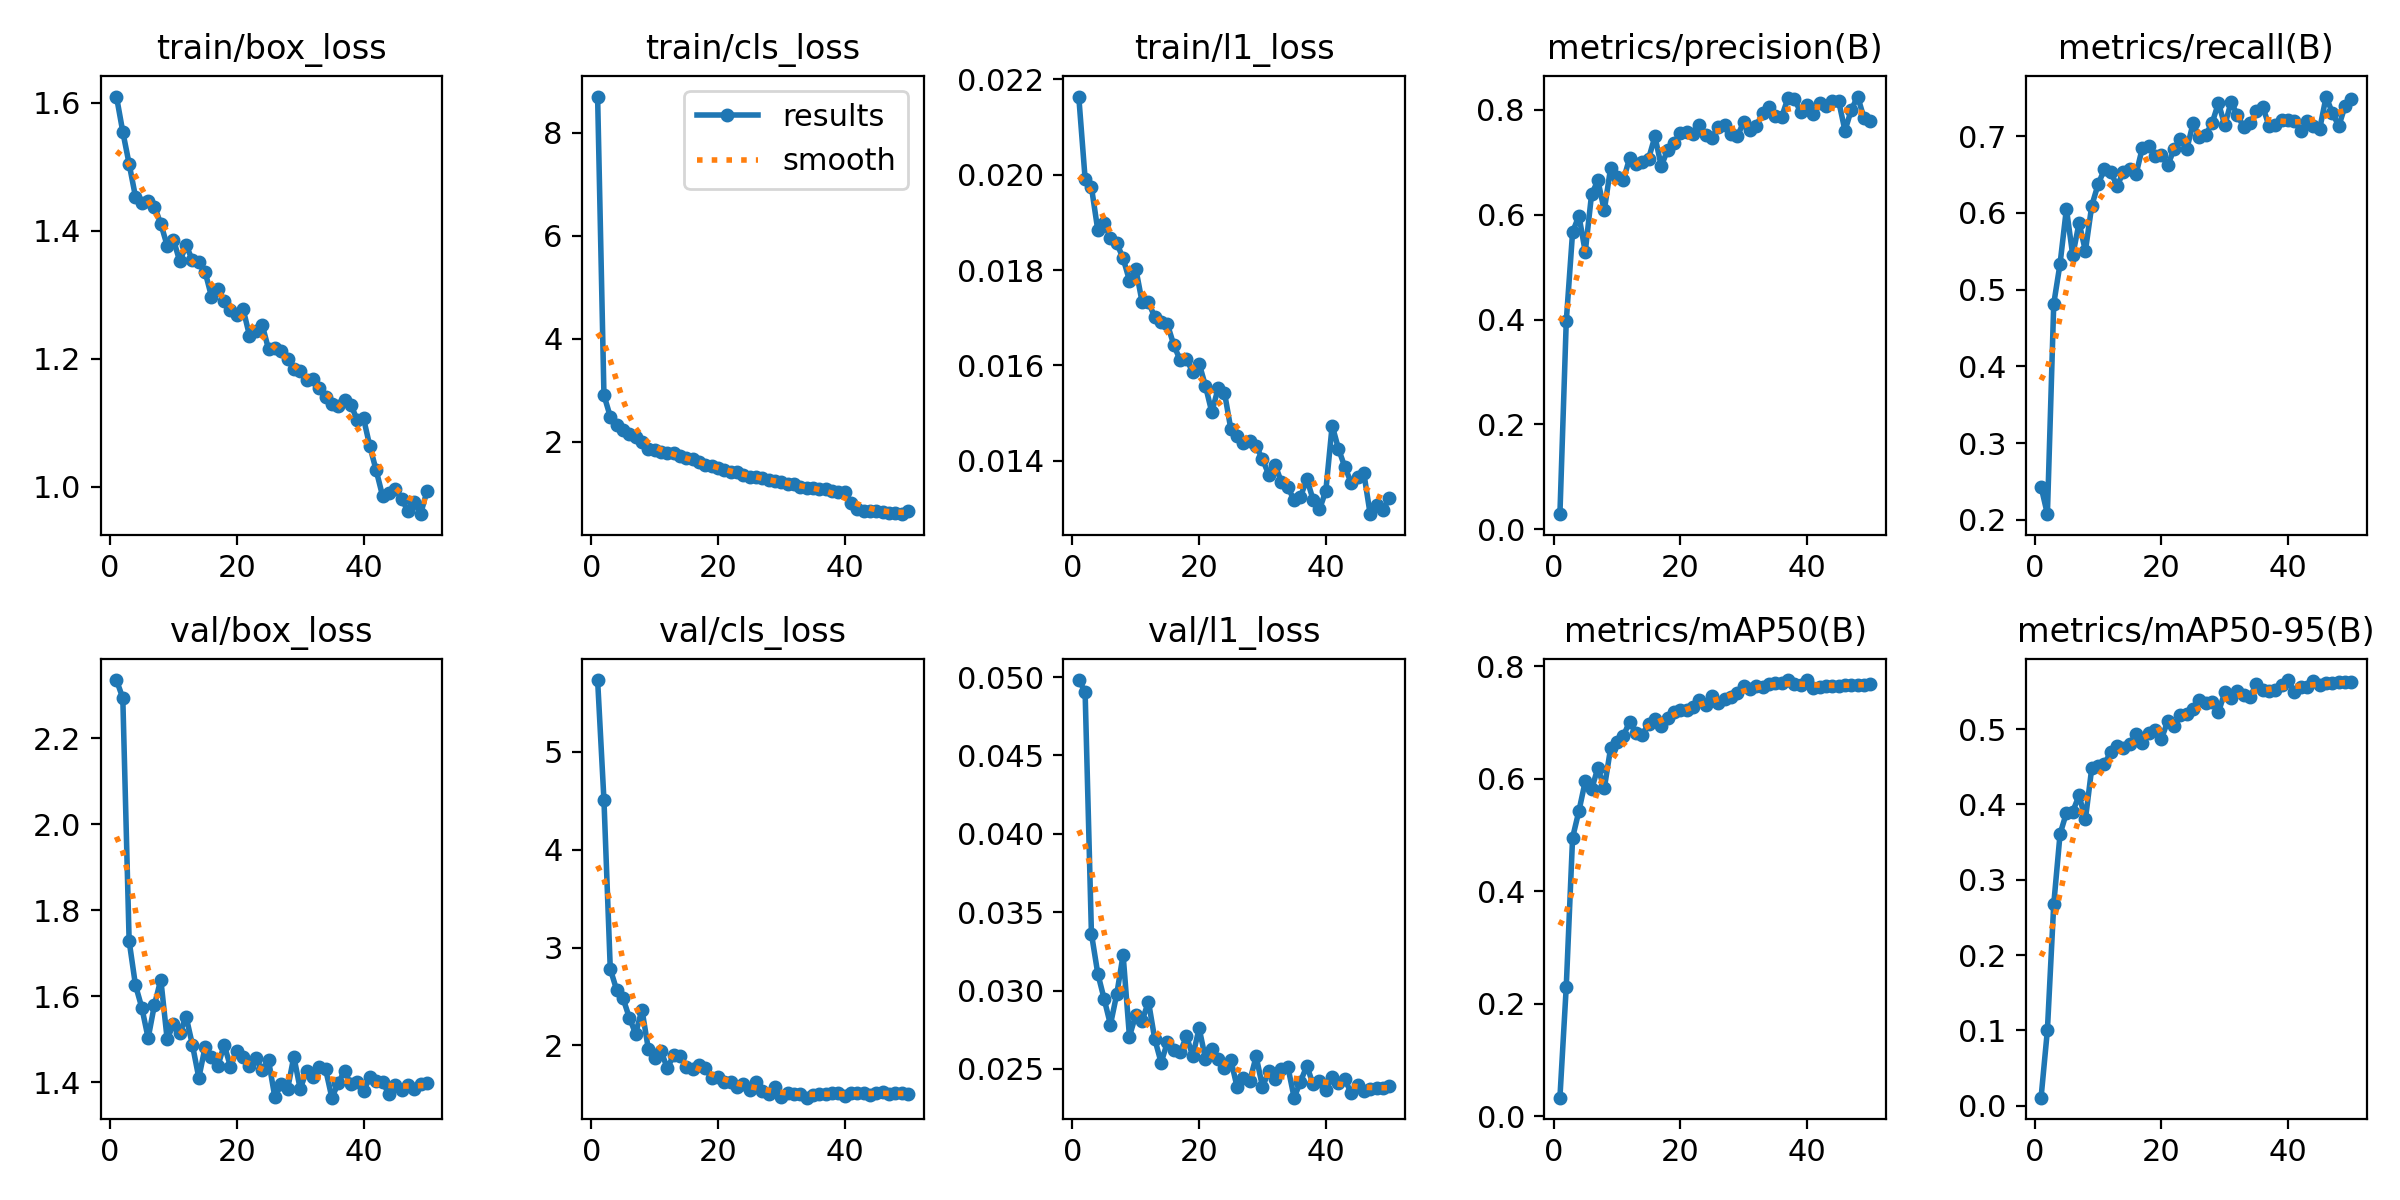

confusion_matrix.png


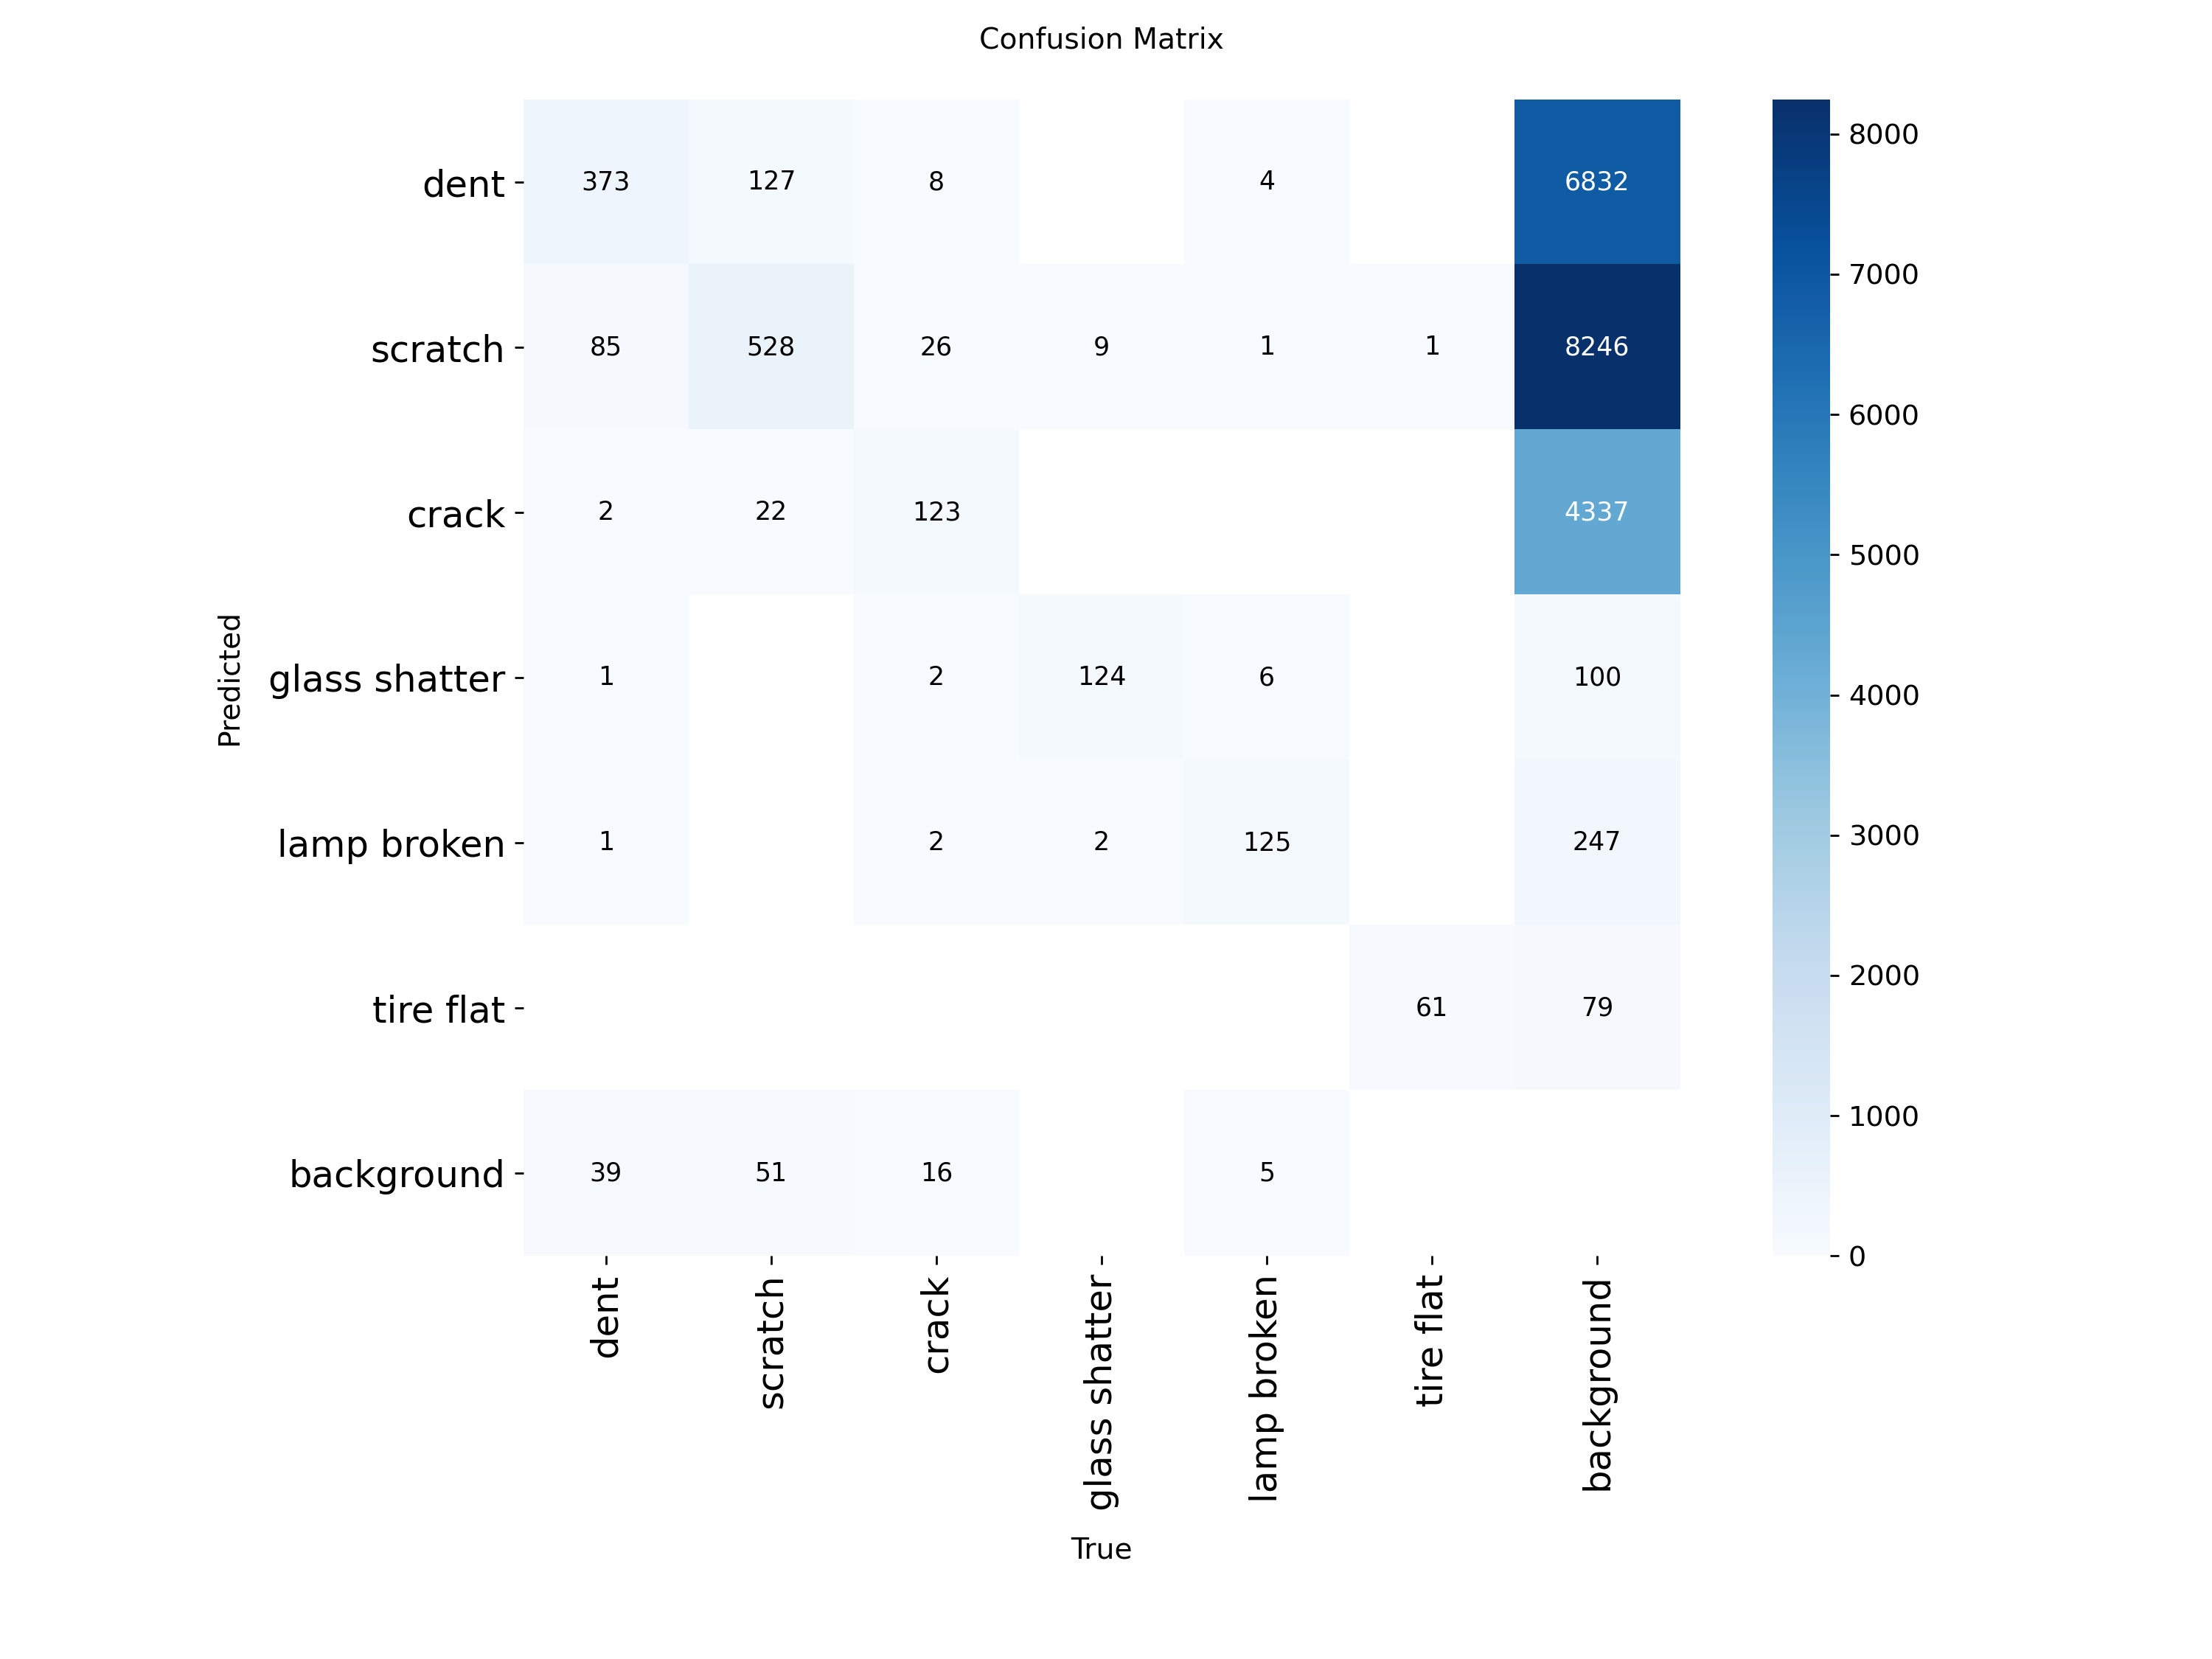

In [8]:
from IPython.display import display, Image

for filename in [
    "results.png",
    "confusion_matrix.png",
    "PR_curve.png",
    "F1_curve.png",
]:
    plot_path = run_dir / filename

    if plot_path.exists():
        print(filename)
        display(Image(filename=str(plot_path)))

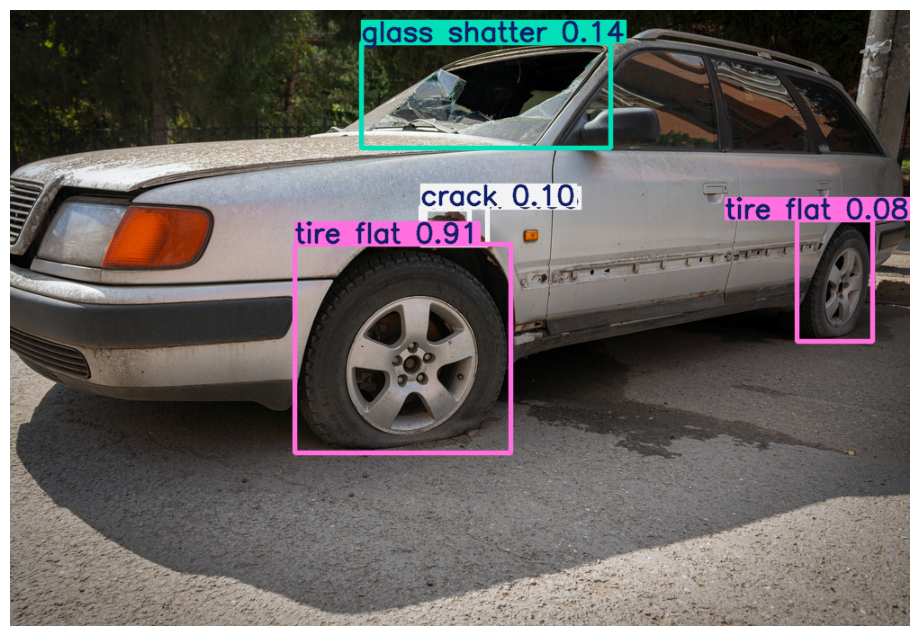

Image: 000013.jpg


In [9]:
import cv2
import matplotlib.pyplot as plt

image_dir = BASE / "val/images"

image_files = sorted([
    p for p in image_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
])

assert image_files, "No validation images found."

image_path = image_files[0]

prediction = best_model.predict(
    source=str(image_path),
    imgsz=1024,
    conf=0.05,
    device=0,
    verbose=False
)[0]

annotated_image = prediction.plot()

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

print("Image:", image_path.name)

In [12]:
import os
import shutil
from pathlib import Path
from IPython.display import FileLink, display

os.chdir("/kaggle/working")

# Create ZIP of the complete runs folder
shutil.make_archive(
    "runs",
    "zip",
    root_dir="/kaggle/working",
    base_dir="runs"
)

# Verify the file exists
assert Path("runs.zip").exists(), "ZIP file was not created"

print("ZIP size:", round(Path("runs.zip").stat().st_size / (1024**2), 2), "MB")

# IMPORTANT: use the relative filename
display(FileLink("runs.zip"))

ZIP size: 486.13 MB


/kaggle/working/runs.zip